# 02 · YOLOv8-seg nhận dạng vùng ngập

Mô tả bộ dữ liệu ảnh thật `datasets/vision/flood_area_real` (Kaggle Flood Area Segmentation, CC0), đo chỉ số của mô hình đang kích hoạt trên tập test và xem vài dự đoán. Notebook chỉ **đọc** CSDL (để biết mô hình nào đang chạy) và không huấn luyện.

In [1]:
import os, sys
from pathlib import Path
os.environ.setdefault("PYTHONUTF8", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
BACKEND = ROOT / "backend"
sys.path.insert(0, str(BACKEND))
os.chdir(BACKEND)  # để đọc backend/.env
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
import cv2
DS = ROOT / "datasets" / "vision" / "flood_area_real"

## 1. Bộ dữ liệu

In [2]:
rows = []
for sp in ("train", "val", "test"):
    imgs = sorted((DS / "images" / sp).glob("*.jpg")); labs = list((DS / "labels" / sp).glob("*.txt"))
    empty = sum(1 for p in labs if not p.read_text(encoding="utf-8").strip())
    rows.append({"tập": sp, "ảnh": len(imgs), "nhãn": len(labs), "nhãn rỗng": empty})
display(pd.DataFrame(rows)); print((DS / "data.yaml").read_text(encoding="utf-8"))

,tập,ảnh,nhãn,nhãn rỗng
0,train,203,203,0
1,val,43,43,0
2,test,44,44,0


# Kaggle Flood Area Segmentation (faizalkarim, CC0) - ảnh THẬT, mask -> polygon
path: E:/Octotusmap/datasets/vision/flood_area_real
train: images/train
val: images/val
test: images/test
names:
  0: flood_water



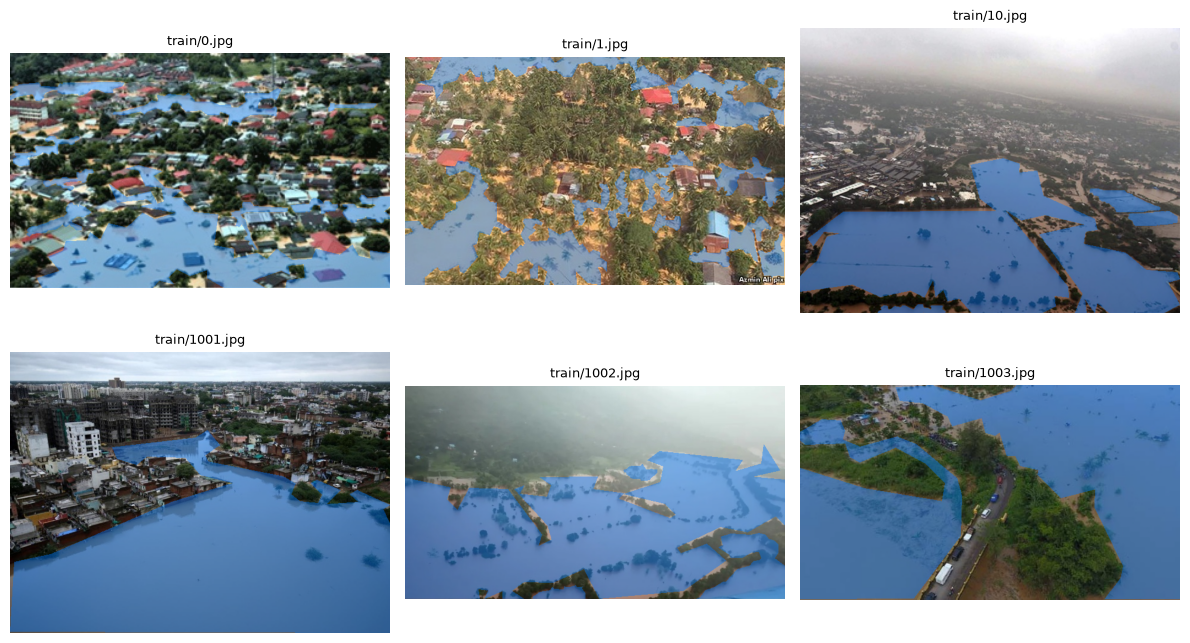

In [3]:
def draw(name, sp, ax):
    img = cv2.cvtColor(cv2.imread(str(DS / "images" / sp / name)), cv2.COLOR_BGR2RGB); h, w = img.shape[:2]
    for line in (DS / "labels" / sp / (Path(name).stem + ".txt")).read_text(encoding="utf-8").splitlines():
        v = line.split(); pts = (np.array(v[1:], float).reshape(-1, 2) * [w, h]).astype(np.int32)
        ov = img.copy(); cv2.fillPoly(ov, [pts], (0, 120, 255)); img = cv2.addWeighted(ov, .45, img, .55, 0)
    ax.imshow(img); ax.set_title(f"{sp}/{name}", fontsize=9); ax.axis("off")
names = sorted(p.name for p in (DS / "images" / "train").glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for n, ax in zip(names, axes.ravel()): draw(n, "train", ax)
plt.tight_layout(); plt.show()

## 2. Mô hình đang kích hoạt

In [4]:
from app.core.database import SessionLocal
from app.services.camera_service import active_vision_model
with SessionLocal() as db:
    mv = active_vision_model(db)
    info = None if mv is None else {"version": mv.version, "weights": mv.artifact_path, "metrics": mv.metrics}
print(info)
assert info and Path(info["weights"]).exists(), "Chưa có mô hình YOLOv8-seg đang kích hoạt"

{'version': '20261112044316', 'weights': 'E:\\Octotusmap\\backend\\app\\ai\\artifacts\\vision\\yolov8n-seg-20261112044316\\best.pt', 'metrics': {'box_map50': 0.5151879627561264, 'box_map50_95': 0.3162581272406487, 'mask_map50': 0.45030130732443396, 'mask_map50_95': 0.20726769336959458, 'precision': 0.5724518329421588, 'recall': 0.4826336556062924}}


## 3. Chỉ số trên tập test

Tính lại bằng `ultralytics` (`imgsz=320`, CPU) để kiểm chứng, đối chiếu với chỉ số lưu lúc huấn luyện.

In [5]:
from app.ai.computer_vision.train import evaluate
m = evaluate(info["weights"], DS / "data.yaml", split="test")
display(pd.DataFrame({"đo lại (test)": m}).round(3))
print("Lưu lúc huấn luyện:", info["metrics"])

Ultralytics 8.4.197  Python-3.13.16 torch-2.15.0+cpu CPU (11th Gen Intel Core i7-11850H @ 2.50GHz)


YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 1230.9±324.1 MB/s, size: 96.8 KB)


val: Scanning E:\Octotusmap\datasets\vision\flood_area_real\labels\test.cache... 44 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 8.0Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 33% ━━━━──────── 1/3 1.2s/it 0.4s<2.4s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 66% ━━━━━━━━──── 2/3 1.4it/s 0.8s<0.7s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.7it/s 1.1s

                   all         44        172      0.597      0.517      0.515      0.316      0.572      0.483       0.45      0.207


Speed: 0.6ms preprocess, 17.0ms inference, 0.0ms loss, 2.2ms postprocess per image


,đo lại (test)
box_map50,0.515
box_map50_95,0.316
mask_map50,0.450
mask_map50_95,0.207
precision,0.572
recall,0.483


Lưu lúc huấn luyện: {'box_map50': 0.5151879627561264, 'box_map50_95': 0.3162581272406487, 'mask_map50': 0.45030130732443396, 'mask_map50_95': 0.20726769336959458, 'precision': 0.5724518329421588, 'recall': 0.4826336556062924}


## 4. Dự đoán trên ảnh test

Vùng tô màu là mask do mô hình dự đoán (qua `detector.detect`, cùng đường chạy với camera).

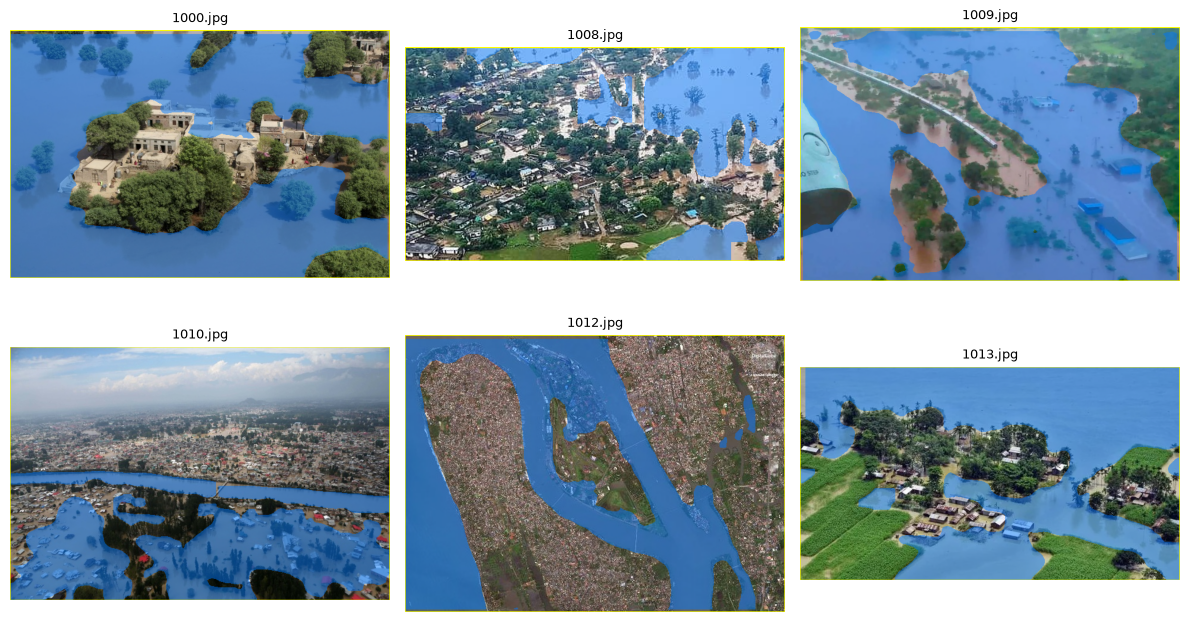

In [6]:
from app.ai.computer_vision import detector
tests = sorted((DS / "images" / "test").glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for p, ax in zip(tests, axes.ravel()):
    r = detector.detect(cv2.imread(str(p)), roi=[[0, 0], [1, 0], [1, 1], [0, 1]], weights=info["weights"])
    ax.imshow(cv2.cvtColor(r.overlay, cv2.COLOR_BGR2RGB)); ax.set_title(f"{p.name}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Nhận xét.** Ảnh thật là cảnh ngập ngoài trời đa dạng, không phải camera giao thông TP.HCM; chỉ số chỉ nói về khả năng tách vùng nước ngập trên tập này. Hệ thống không chạy YOLO trên ảnh camera giao thông thật (xem `docs/known-limitations.md`).